# Imbalanced Learning Techniques for Music Classification

## Experiment Overview

**Author:** Giuseppe
**Institution:** University of Pisa
**Program:** Master's Degree in Computer Science
**Specialization:** Data Science & Business Informatics

---

## Research Objective

This experiment investigates the effectiveness of different imbalanced learning techniques for binary classification of explicit content in music tracks. The study compares various sampling strategies to address class imbalance in a real-world music dataset.

## Dataset Context

The dataset contains music track features with a significant class imbalance:
- **Majority class (Non-explicit):** ~91% of samples
- **Minority class (Explicit):** ~9% of samples

This severe imbalance presents a typical challenge in machine learning where standard classification algorithms tend to favor the majority class, resulting in poor performance on the minority class.

## Methodology

The experiment evaluates four different approaches:

1. **Baseline:** Standard RandomForestClassifier without balancing techniques
2. **SMOTE:** Synthetic Minority Oversampling Technique
3. **Tomek + Undersampling:** Combined noise removal and majority class reduction
4. **SMOTE + Tomek:** Hybrid approach combining oversampling and boundary cleaning

## Evaluation Framework

Performance is assessed using appropriate metrics for imbalanced classification:
- **F1-score (macro):** Primary metric for balanced evaluation
- **Precision and Recall (macro):** Class-agnostic performance measures
- **ROC AUC:** Threshold-independent performance indicator
- **Class-specific metrics:** Detailed analysis of minority class performance

The evaluation emphasizes the trade-off between precision and recall, particularly focusing on the model's ability to correctly identify the minority class while maintaining overall performance.

In [1]:
from __future__ import annotations

import matplotlib.pyplot as plt
import seaborn as sns
import multiprocessing
import os, sys, time, ast
import math
import pandas as pd
import numpy as np
from imblearn.pipeline import Pipeline
from imblearn.combine import SMOTETomek
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    ConfusionMatrixDisplay
)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold


import warnings

from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')

# --- IMPOSTAZIONI GLOBALI PER I GRAFICI ---
# Stile base
plt.style.use("dark_background")
sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette="icefire",
    font="sans-serif",
    font_scale=1.1
)

# Aggiornamenti avanzati
plt.rcParams.update({
    # Colori e sfondi
    'figure.facecolor': '#111111',
    'axes.facecolor': '#111111',
    'savefig.facecolor': '#111111',
    'axes.edgecolor': 'white',
    'axes.labelcolor': 'white',
    'axes.titlecolor': 'white',
    'text.color': 'white',
    'xtick.color': 'lightgray',
    'ytick.color': 'lightgray',

    # Font e peso
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',

    # Griglia elegante
    'axes.grid': True,
    'grid.color': 'gray',
    'grid.linestyle': '--',
    'grid.linewidth': 0.4,
    'grid.alpha': 0.3,  # meno invasiva

    # Tick leggeri
    'xtick.direction': 'out',
    'ytick.direction': 'out',

    # Leggibilità generale
    'legend.edgecolor': 'gray',
    'legend.facecolor': '#222222',
    'legend.fontsize': 'medium',
})

print("✅ Impostazioni grafiche caricate.")

# --- CREAZIONE DIRECTORY PER I MODELLI ---
# print("--- Creazione directory per i modelli ---")
# models_dir = 'models_time_series_classification/'
# os.makedirs(models_dir, exist_ok=True)
# print(f"✅ Directory per i modelli '{models_dir}' pronta.")

# --- CREAZIONE DIRECTORY PER I PLOT ---
plots_dir = 'plots_imbalanced_learning/'
os.makedirs(plots_dir, exist_ok=True)
print(f"✅ Directory per i grafici '{plots_dir}' pronta.")

# --- CARICAMENTO DEL DATASET PREPARATO ---
dataset_dir = "Dataset/"
dataset_name = "spotify_cleaned.csv"
try:
    df = pd.read_csv(os.path.join(dataset_dir, dataset_name))
    print(f"✅ Dataset preparato caricato: {df.shape[0]} righe, {df.shape[1]} colonne.")
except FileNotFoundError as e:
    print(f"❌ Errore: File non trovato. Assicurati di aver eseguito il Modulo 0 e salvato '{dataset_name}'.")
    sys.exit(1)


✅ Impostazioni grafiche caricate.
✅ Directory per i grafici 'plots_imbalanced_learning/' pronta.
✅ Dataset preparato caricato: 108299 righe, 66 colonne.


In [2]:
df.head(10)

,artists,album_name,track_name,popularity,explicit,danceability,energy,loudness,speechiness,acousticness,...,genres_10_Classical/Ambient & Stage,genres_10_Country/Folk & Songwriter,genres_10_Electronic & Dance,genres_10_Hip-Hop & R&B,genres_10_Jazz/Soul/Funk/Blues,genres_10_Latin & Brazilian,genres_10_Metal & Hardcore,genres_10_Pop & Indie,genres_10_Rock & Alternative,genres_10_World & Regional
0,Gen Hoshino,Comedy,Comedy,73,0,0.676,0.4610,-6.746,0.1430,0.0322,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,0,0.420,0.1660,-17.235,0.0763,0.9240,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,0,0.438,0.3590,-9.734,0.0557,0.2100,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,0,0.266,0.0596,-18.515,0.0363,0.9050,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Chord Overstreet,Hold On,Hold On,82,0,0.618,0.4430,-9.681,0.0526,0.4690,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,Tyrone Wells,Days I Will Remember,Days I Will Remember,58,0,0.688,0.4810,-8.807,0.1050,0.2890,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,A Great Big World;Christina Aguilera,Is There Anybody Out There?,Say Something,74,0,0.407,0.1470,-8.822,0.0355,0.8570,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,Jason Mraz,We Sing. We Dance. We Steal Things.,I'm Yours,80,0,0.703,0.4440,-9.331,0.0417,0.5590,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,Jason Mraz;Colbie Caillat,We Sing. We Dance. We Steal Things.,Lucky,74,0,0.625,0.4140,-8.700,0.0369,0.2940,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,Ross Copperman,Hunger,Hunger,56,0,0.442,0.6320,-6.770,0.0295,0.4260,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


=== Imbalanced Dataset Report ===
Non-explicit class (0): 99181 samples
Explicit class (1):     9118 samples
Imbalance ratio:        9.19% (explicit / non-explicit)



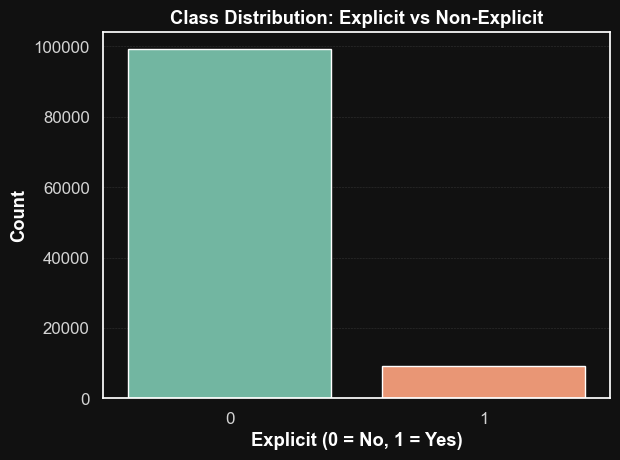

In [5]:
# Analisi distribuzione variabile "explicit" per comprendere l'entità dello sbilanciamento
explicit_counts = df['explicit'].value_counts()

n_non_explicit = explicit_counts.get(0, 0)
n_explicit = explicit_counts.get(1, 0)
imbalance_ratio = (n_explicit / n_non_explicit * 100) if n_non_explicit > 0 else np.nan

print("=== Imbalanced Dataset Report ===")
print(f"Non-explicit class (0): {n_non_explicit} samples")
print(f"Explicit class (1):     {n_explicit} samples")
print(f"Imbalance ratio:        {imbalance_ratio:.2f}% (explicit / non-explicit)\n")

sns.countplot(data=df, x="explicit", palette="Set2")
plt.title("Class Distribution: Explicit vs Non-Explicit")
plt.xlabel("Explicit (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


In [4]:
from sklearn.model_selection import train_test_split
columns_to_use = []
for col in df.columns:
    if col.startswith("std_") or col.startswith("genres_10_") or col.startswith("keymode_"):
        if col != "std_explicit" and col != "explicit":
            columns_to_use.append(col)

X = df[columns_to_use].copy()
y = df["explicit"].copy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [30]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 86639 entries, 15866 to 29390
Data columns (total 46 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   std_popularity                       86639 non-null  float64
 1   std_danceability                     86639 non-null  float64
 2   std_energy                           86639 non-null  float64
 3   std_loudness                         86639 non-null  float64
 4   std_speechiness                      86639 non-null  float64
 5   std_acousticness                     86639 non-null  float64
 6   std_instrumentalness                 86639 non-null  float64
 7   std_liveness                         86639 non-null  float64
 8   std_valence                          86639 non-null  float64
 9   std_tempo                            86639 non-null  float64
 10  std_time_signature                   86639 non-null  float64
 11  std_duration_mins            

In [6]:
y_train

15866     0
8127      0
58885     0
73003     0
72728     0
         ..
52804     0
93268     0
96219     0
108198    0
29390     0
Name: explicit, Length: 86639, dtype: int64

### BASELINE RandomForestClassifier (we're not using any balancing techniques)

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Griglia iperparametri
param_grid = {
    "n_estimators": [300],
    "max_depth": [None, 20, 30],
    "min_samples_split": [2, 3],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt"],
    "criterion": ["gini", "entropy"]
}

# Classificatore base
rf = RandomForestClassifier(
    n_jobs=-1,
    random_state=42,
    oob_score=False,
    class_weight=None  # nessun bilanciamento per ora
)

# Stratified K-Fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# GridSearch
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1,
    return_train_score=False,
    refit=True
)

# Fit
grid_search.fit(X_train, y_train)

# Best params
best_rf_model = grid_search.best_estimator_
best_rf_params = grid_search.best_params_

print("✅ Migliori iperparametri trovati:")
for k, v in best_rf_params.items():
    print(f"{k}: {v}")


Fitting 5 folds for each of 24 candidates, totalling 120 fits
✅ Migliori iperparametri trovati:
criterion: entropy
max_depth: None
max_features: sqrt
min_samples_leaf: 1
min_samples_split: 2
n_estimators: 300


=== METRICHE COMPLETE ===
Accuracy        : 0.9454
F1-score (macro): 0.7600
Recall (macro)  : 0.6954
Precision (macro): 0.9241
ROC AUC         : 0.9448

=== Classification Report ===
              precision    recall  f1-score   support

           0     0.9471    0.9960    0.9709     19836
           1     0.9011    0.3947    0.5490      1824

    accuracy                         0.9454     21660
   macro avg     0.9241    0.6954    0.7600     21660
weighted avg     0.9432    0.9454    0.9354     21660

=== Confusion Matrix ===
[[19757    79]
 [ 1104   720]]


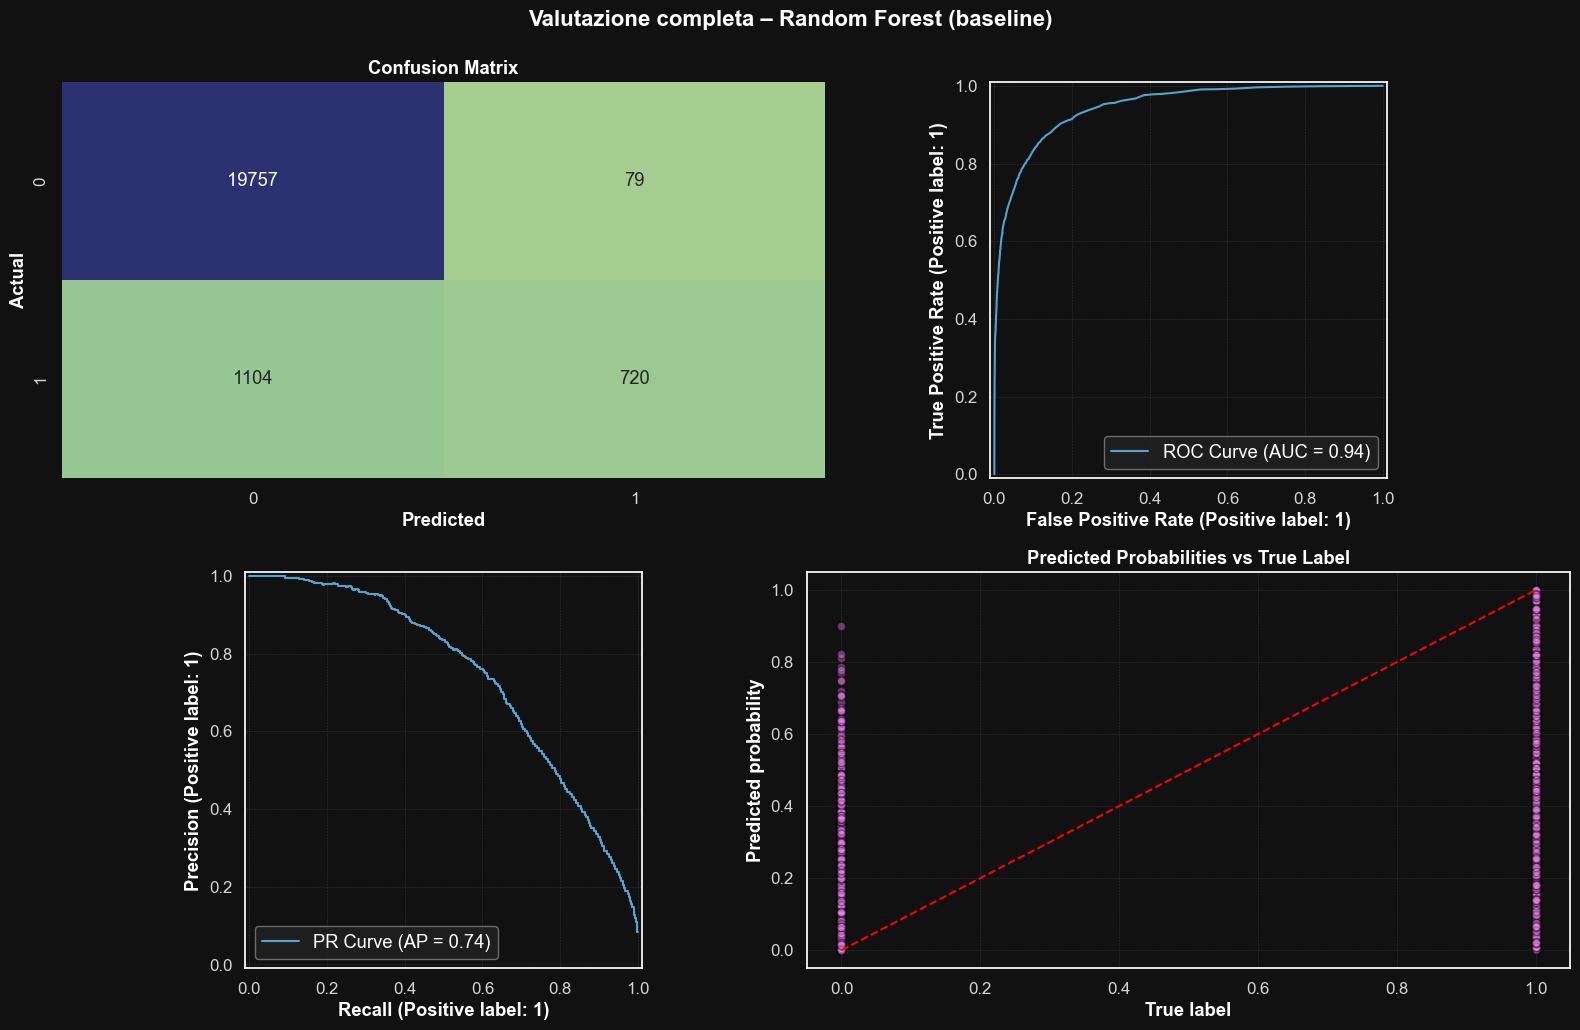

In [8]:
# Predizioni finali sul test set
y_pred = best_rf_model.predict(X_test)
y_proba = best_rf_model.predict_proba(X_test)[:, 1]

# METRICHE
print("=== METRICHE COMPLETE ===")
print(f"Accuracy        : {accuracy_score(y_test, y_pred):.4f}")
print(f"F1-score (macro): {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"Recall (macro)  : {recall_score(y_test, y_pred, average='macro'):.4f}")
print(f"Precision (macro): {precision_score(y_test, y_pred, average='macro'):.4f}")
print(f"ROC AUC         : {roc_auc_score(y_test, y_proba):.4f}")

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred, digits=4))

print("=== Confusion Matrix ===")
cm = confusion_matrix(y_test, y_pred)
print(cm)

# GRAFICI
plt.figure(figsize=(16, 10))

# 1. Confusion Matrix
plt.subplot(2, 2, 1)
sns.heatmap(cm, annot=True, fmt='d', cmap="crest", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

# 2. ROC Curve
plt.subplot(2, 2, 2)
RocCurveDisplay.from_predictions(y_test, y_proba, ax=plt.gca(), name="ROC Curve")

# 3. Precision-Recall Curve
plt.subplot(2, 2, 3)
PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=plt.gca(), name="PR Curve")

# 4. Predicted vs True Probabilities
plt.subplot(2, 2, 4)
plt.scatter(y_test, y_proba, alpha=0.4, color='violet', edgecolors='k')
plt.plot([0, 1], [0, 1], "r--")
plt.xlabel("True label")
plt.ylabel("Predicted probability")
plt.title("Predicted Probabilities vs True Label")

plt.tight_layout()
plt.suptitle("Valutazione completa – Random Forest (baseline)", y=1.03, fontsize=16, fontweight="bold")
plt.show()


### SMOTE + RandomForestClassifier pipeline

In [11]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Pipeline: SMOTE + RandomForestClassifier
pipeline = Pipeline(steps=[
    ("smote", SMOTE(random_state=42)),
    ("rf", RandomForestClassifier(random_state=42, n_jobs=-1))
])

# Griglia iperparametri per RandomForest
param_grid = {
    "rf__n_estimators": [300],
    "rf__max_depth": [20, 30, None],
    "rf__min_samples_split": [2, 3],
    "rf__min_samples_leaf": [1, 2],
    "rf__max_features": ["sqrt"],
    "rf__criterion": ["entropy"]
}

# Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# GridSearchCV
grid_search_smote = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    verbose=1,
    n_jobs=-1,
    return_train_score=False,
    refit=True
)

# Fit
grid_search_smote.fit(X_train, y_train)

# Best model e parametri
best_smote_rf_model = grid_search_smote.best_estimator_
best_smote_rf_params = grid_search_smote.best_params_

# Report iperparametri
print("✅ Migliori iperparametri con SMOTE:")
for k, v in best_smote_rf_params.items():
    print(f"{k}: {v}")


Fitting 5 folds for each of 12 candidates, totalling 60 fits
✅ Migliori iperparametri con SMOTE:
rf__criterion: entropy
rf__max_depth: None
rf__max_features: sqrt
rf__min_samples_leaf: 1
rf__min_samples_split: 2
rf__n_estimators: 300


=== SMOTE + RandomForestClassifier ===
Accuracy        : 0.9365
F1-score (macro): 0.7951
Precision (macro): 0.7938
Recall (macro)  : 0.7963
ROC AUC         : 0.9411

=== Classification Report ===
              precision    recall  f1-score   support

           0     0.9657    0.9649    0.9653     19836
           1     0.6219    0.6277    0.6248      1824

    accuracy                         0.9365     21660
   macro avg     0.7938    0.7963    0.7951     21660
weighted avg     0.9368    0.9365    0.9367     21660

=== Confusion Matrix ===
[[19140   696]
 [  679  1145]]


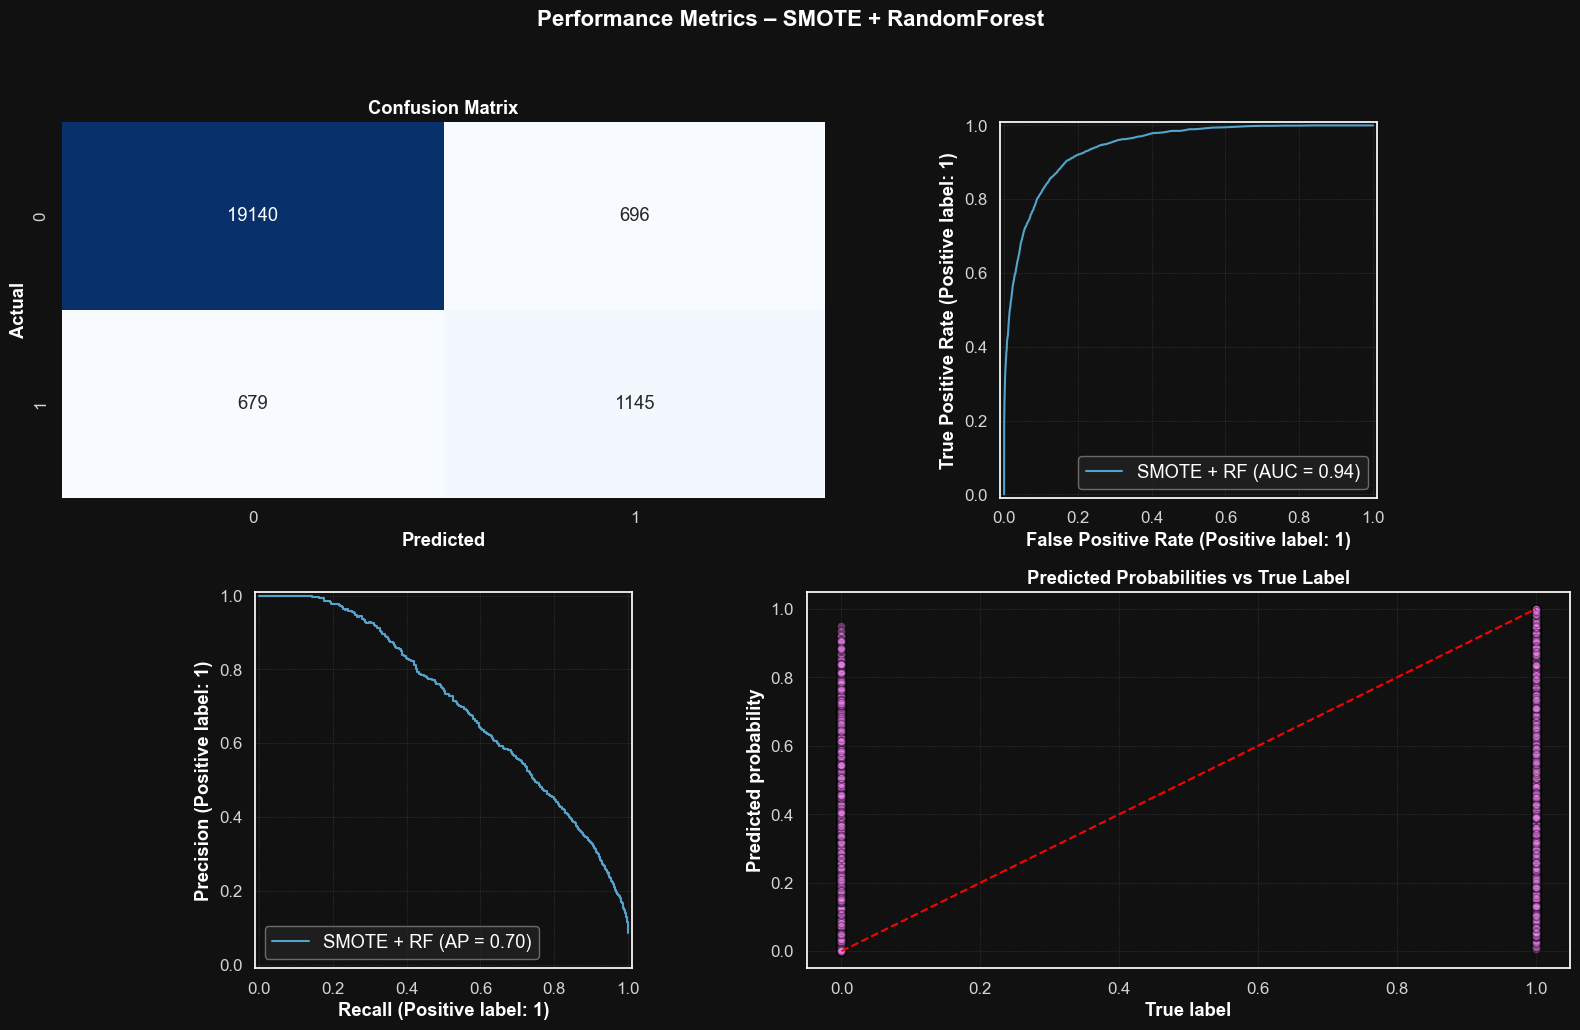

In [12]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# Predizioni
y_pred_smote = best_smote_rf_model.predict(X_test)
y_proba_smote = best_smote_rf_model.predict_proba(X_test)[:, 1]

# METRICHE GLOBALI
accuracy = accuracy_score(y_test, y_pred_smote)
f1 = f1_score(y_test, y_pred_smote, average="macro")
precision = precision_score(y_test, y_pred_smote, average="macro")
recall = recall_score(y_test, y_pred_smote, average="macro")
roc_auc = roc_auc_score(y_test, y_proba_smote)

# PRINT METRICHE
print("=== SMOTE + RandomForestClassifier ===")
print(f"Accuracy        : {accuracy:.4f}")
print(f"F1-score (macro): {f1:.4f}")
print(f"Precision (macro): {precision:.4f}")
print(f"Recall (macro)  : {recall:.4f}")
print(f"ROC AUC         : {roc_auc:.4f}\n")

# REPORT E CONFUSION MATRIX
print("=== Classification Report ===")
print(classification_report(y_test, y_pred_smote, digits=4))

cm = confusion_matrix(y_test, y_pred_smote)
print("=== Confusion Matrix ===")
print(cm)

# GRAFICI COMPLETI
plt.figure(figsize=(16, 10))

# Confusion Matrix
plt.subplot(2, 2, 1)
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

# ROC Curve
plt.subplot(2, 2, 2)
RocCurveDisplay.from_predictions(y_test, y_proba_smote, ax=plt.gca(), name="SMOTE + RF")

# Precision-Recall Curve
plt.subplot(2, 2, 3)
PrecisionRecallDisplay.from_predictions(y_test, y_proba_smote, ax=plt.gca(), name="SMOTE + RF")

# Predicted Probabilities vs True
plt.subplot(2, 2, 4)
plt.scatter(y_test, y_proba_smote, alpha=0.4, color='violet', edgecolors='k')
plt.plot([0, 1], [0, 1], "r--")
plt.xlabel("True label")
plt.ylabel("Predicted probability")
plt.title("Predicted Probabilities vs True Label")

plt.suptitle("Performance Metrics – SMOTE + RandomForest", fontsize=16, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()


## Confronto tra Baseline e SMOTE

| **Metrica**        | **Baseline (RF)** | **SMOTE + RF** |
|--------------------|------------------:|----------------:|
| F1-score (macro)   | 0.7600            | **0.7951**      |
| Precision (macro)  | **0.9241**        | 0.7938          |
| Recall (macro)     | 0.6954            | **0.7963**      |
| ROC AUC            | **0.9448**        | 0.9411          |

### Interpretazione

- **SMOTE migliora nettamente il **Recall** sulla classe minoritaria** (da **0.3947 → 0.6277**) e aumenta il F1 macro (**da 0.76 → 0.7951**), segno che il modello è più equo e sensibile verso la classe 1.
- La **Precision** cala leggermente con SMOTE, effetto atteso del bilanciamento: il modello commette più falsi positivi, ma cattura molti più veri positivi.

- **Conclusione**: il modello SMOTE + RF è più bilanciato e adatto in contesti di fairness o anomaly detection, mentre il modello baseline è più conservativo ma penalizza la classe minoritaria.
- L'accuracy l'abbiamo ovviamente ignorata, perchè in questi contesti estremamente bilanciati, anche un modello stupido che predice sempre la classe maggioritaria ha il 91% di prenderci sempre...
---


#### Tecniche di Undersampling: TOMEK-LINKS più undersampling della classe maggioritaria

In [13]:
from imblearn.under_sampling import TomekLinks, RandomUnderSampler
from imblearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Pipeline: prima pulizia con Tomek Links, poi undersampling casuale
under_pipeline = Pipeline(steps=[
    ('tomek', TomekLinks(sampling_strategy='auto', n_jobs=-1)),
    ('undersample', RandomUnderSampler(sampling_strategy='auto', random_state=42)),
    ('clf', RandomForestClassifier(
        class_weight=None,
        bootstrap=True,
        n_jobs=-1,
        random_state=42,
        oob_score=False
    ))
])

# Griglia iperparametri
param_grid = {
    'clf__n_estimators': [300],
    'clf__max_depth': [None],
    'clf__min_samples_split': [2],
    'clf__min_samples_leaf': [1],
    'clf__max_features': ['sqrt'],
    'clf__criterion': ['entropy']
}

# Stratified K-Fold per rispetto proporzioni classe minoritaria
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search_under = GridSearchCV(
    estimator=under_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="f1_macro",
    verbose=1,
    n_jobs=-1,
    refit=True
)

# Fit della pipeline
grid_search_under.fit(X_train, y_train)

# Predizioni finali
y_pred = grid_search_under.predict(X_test)
y_proba = grid_search_under.predict_proba(X_test)[:, 1]

# Migliori parametri trovati
best_under_rf = grid_search_under.best_estimator_
best_params = grid_search_under.best_params_

print("=== Best Parameters (Tomek + Undersampling) ===")
for k, v in best_params.items():
    print(f"{k}: {v}")


Fitting 5 folds for each of 1 candidates, totalling 5 fits
=== Best Parameters (Tomek + Undersampling) ===
clf__criterion: entropy
clf__max_depth: None
clf__max_features: sqrt
clf__min_samples_leaf: 1
clf__min_samples_split: 2
clf__n_estimators: 300


=== Tomek Links + Undersampling ===
Accuracy         : 0.8183
F1-score (macro) : 0.6688
Precision (macro): 0.6428
Recall (macro)   : 0.8415
ROC AUC          : 0.9242

=== Classification Report ===
              precision    recall  f1-score   support

           0     0.9855    0.8136    0.8913     19836
           1     0.3002    0.8695    0.4463      1824

    accuracy                         0.8183     21660
   macro avg     0.6428    0.8415    0.6688     21660
weighted avg     0.9278    0.8183    0.8538     21660

[[16138  3698]
 [  238  1586]]


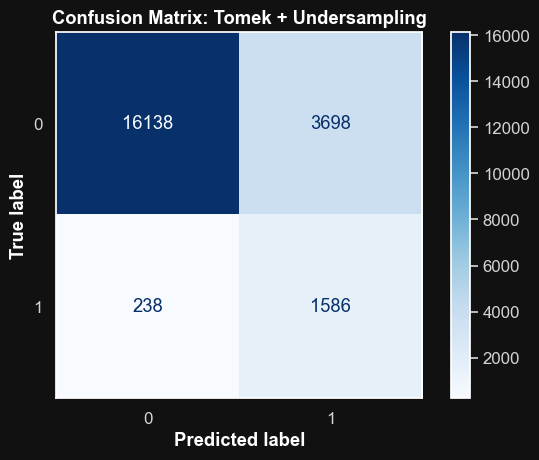

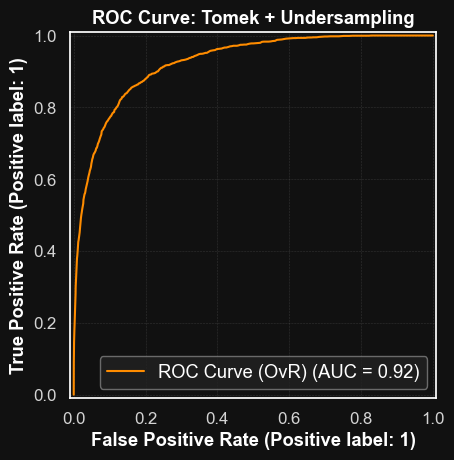

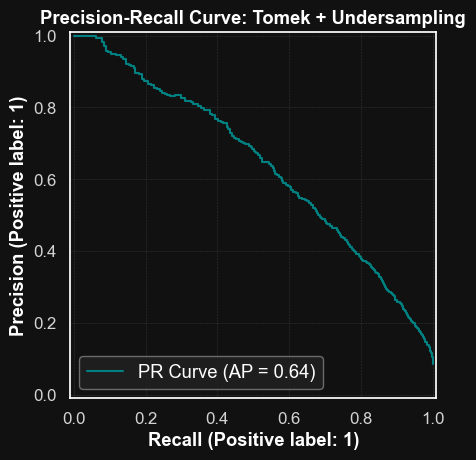

In [15]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    recall_score,
    precision_score
)

# Accuracy
acc = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average='macro')
precision_macro = precision_score(y_test, y_pred, average='macro')
recall_macro = recall_score(y_test, y_pred, average='macro')
roc_auc = roc_auc_score(y_test, y_proba)

# Report completo
print("=== Tomek Links + Undersampling ===")
print(f"Accuracy         : {acc:.4f}")
print(f"F1-score (macro) : {f1_macro:.4f}")
print(f"Precision (macro): {precision_macro:.4f}")
print(f"Recall (macro)   : {recall_macro:.4f}")
print(f"ROC AUC          : {roc_auc:.4f}")
print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred, digits=4))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix: Tomek + Undersampling")
plt.grid(False)
plt.tight_layout()
plt.show()

# ROC Curve
RocCurveDisplay.from_predictions(y_test, y_proba, name="ROC Curve (OvR)", color="darkorange")
plt.title("ROC Curve: Tomek + Undersampling")
plt.grid(True)
plt.tight_layout()
plt.show()

# Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(y_test, y_proba, name="PR Curve", color="teal")
plt.title("Precision-Recall Curve: Tomek + Undersampling")
plt.grid(True)
plt.tight_layout()
plt.show()


### Confronto tra tecniche di bilanciamento

| Metodo                             | F1-score (macro) | Precision (macro) | Recall (macro) | ROC AUC |
|------------------------------------|------------------|-------------------|----------------|---------|
| Baseline (no balancing)            | 0.7600           | 0.9241            | 0.6954         | 0.9448  |
| SMOTE + RandomForestClassifier     | **0.7951**       | 0.7938            | 0.7963         | 0.9411  |
| Tomek Links + Undersampling        | 0.6688           | 0.6428            | **0.8415**     | 0.9242  |

#### Interpretazione

Il metodo **SMOTE + RandomForestClassifier** fornisce il miglior compromesso tra precision e recall, risultando il più efficace in termini di F1-score macro.
È la scelta ottimale per una classificazione equilibrata in presenza di forte sbilanciamento.

La tecnica **Tomek Links + Undersampling** eccelle nel massimizzare il recall, utile per ridurre i falsi negativi, ma lo fa a scapito della precisione.
Potrebbe essere preferibile in contesti in cui è più grave perdere un positivo che aggiungere un falso positivo.

La **baseline**, priva di tecniche di bilanciamento, mostra precisione molto elevata ma recall contenuto, risultando in un numero significativo di falsi negativi. È adatta solo se l’obiettivo è minimizzare gli errori sui negativi.



## Tecnica che unisce SMOTE e TOMEKLinks...

In [18]:
from imblearn.pipeline import Pipeline
from imblearn.combine import SMOTETomek
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Step 1: Pipeline bilanciamento + classificatore
pipeline = Pipeline([
    ('smotetomek', SMOTETomek(random_state=42)),
    ('rf', RandomForestClassifier(
        class_weight=None,
        bootstrap=True,
        n_jobs=-1,
        random_state=42
    ))
])

# Step 2: Grid Search con validazione incrociata
param_grid = {
    'rf__n_estimators': [300],
    'rf__max_depth': [None],
    'rf__min_samples_split': [2, 3],
    'rf__min_samples_leaf': [1, 2],
    'rf__criterion': ['entropy']
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1,
    verbose=1,
    refit=True,
    return_train_score=False,
)

print("Training SMOTETomek + RandomForest pipeline...")
grid_search.fit(X_train, y_train)

# Step 3: Valutazione sul test set originale
best_rf_smotetomek_model = grid_search.best_estimator_
y_pred_smotetomek = best_rf_smotetomek_model.predict(X_test)
y_proba_smotetomek = best_rf_smotetomek_model.predict_proba(X_test)[:, 1]

# === RISULTATI ===
print("="*60)
print("SMOTE + Tomek Links + RandomForestClassifier")
print("="*60)

print(f"\nBest CV Score (F1-macro): {grid_search.best_score_:.4f}")
print("Best RF params:", grid_search.best_params_)

# Metriche finali
acc = accuracy_score(y_test, y_pred_smotetomek)
f1 = f1_score(y_test, y_pred_smotetomek, average="macro")
precision = precision_score(y_test, y_pred_smotetomek, average="macro")
recall = recall_score(y_test, y_pred_smotetomek, average="macro")
roc_auc = roc_auc_score(y_test, y_proba_smotetomek)

print(f"\nMETRICHE FINALI:")
print(f"   Accuracy         : {acc:.4f}")
print(f"   F1-score (macro) : {f1:.4f}")
print(f"   Precision (macro): {precision:.4f}")
print(f"   Recall (macro)   : {recall:.4f}")
print(f"   ROC AUC          : {roc_auc:.4f}")

print(f"\nCLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred_smotetomek, digits=4))

print(f"\nCONFUSION MATRIX:")
cm = confusion_matrix(y_test, y_pred_smotetomek)
print(cm)


Training SMOTETomek + RandomForest pipeline...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
SMOTE + Tomek Links + RandomForestClassifier

Best CV Score (F1-macro): 0.7840
Best RF params: {'rf__criterion': 'entropy', 'rf__max_depth': None, 'rf__min_samples_leaf': 1, 'rf__min_samples_split': 2, 'rf__n_estimators': 300}

METRICHE FINALI:
   Accuracy         : 0.9366
   F1-score (macro) : 0.7947
   Precision (macro): 0.7942
   Recall (macro)   : 0.7951
   ROC AUC          : 0.9408

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0     0.9655    0.9652    0.9654     19836
           1     0.6230    0.6250    0.6240      1824

    accuracy                         0.9366     21660
   macro avg     0.7942    0.7951    0.7947     21660
weighted avg     0.9367    0.9366    0.9366     21660


CONFUSION MATRIX:
[[19146   690]
 [  684  1140]]


<Figure size 800x600 with 0 Axes>

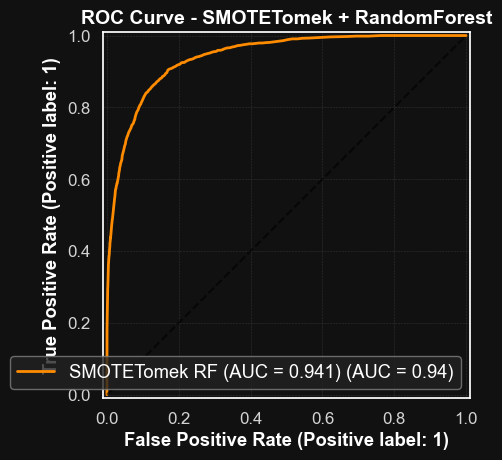

<Figure size 800x600 with 0 Axes>

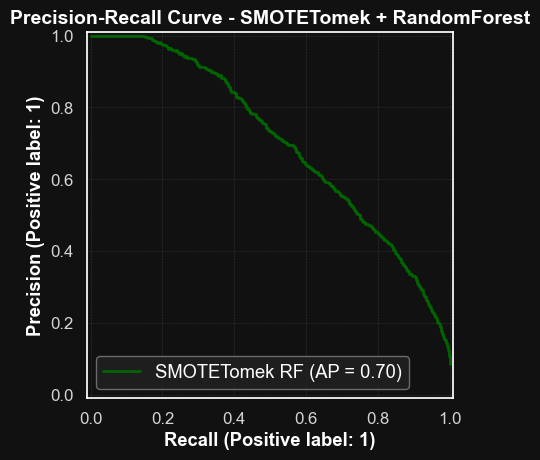

<Figure size 800x600 with 0 Axes>

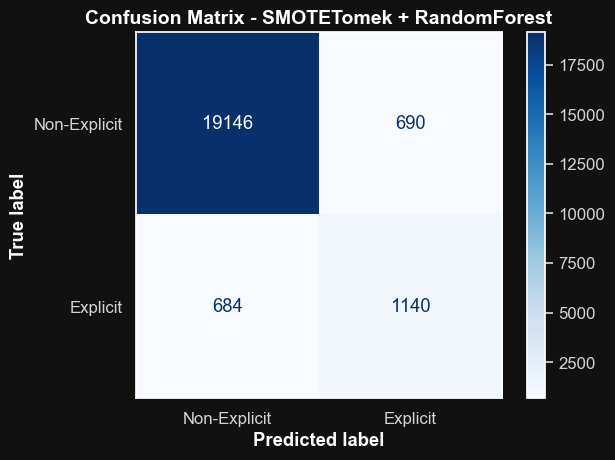

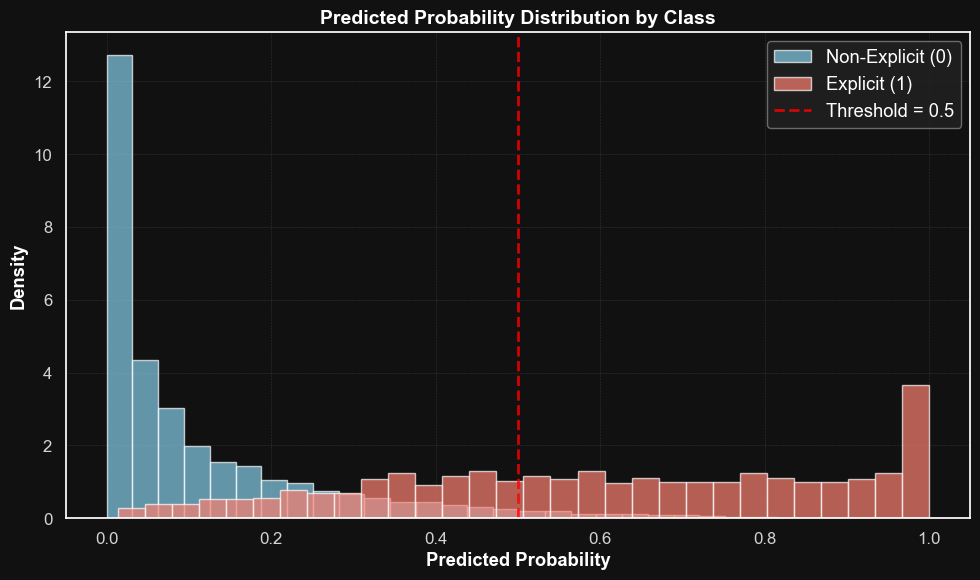

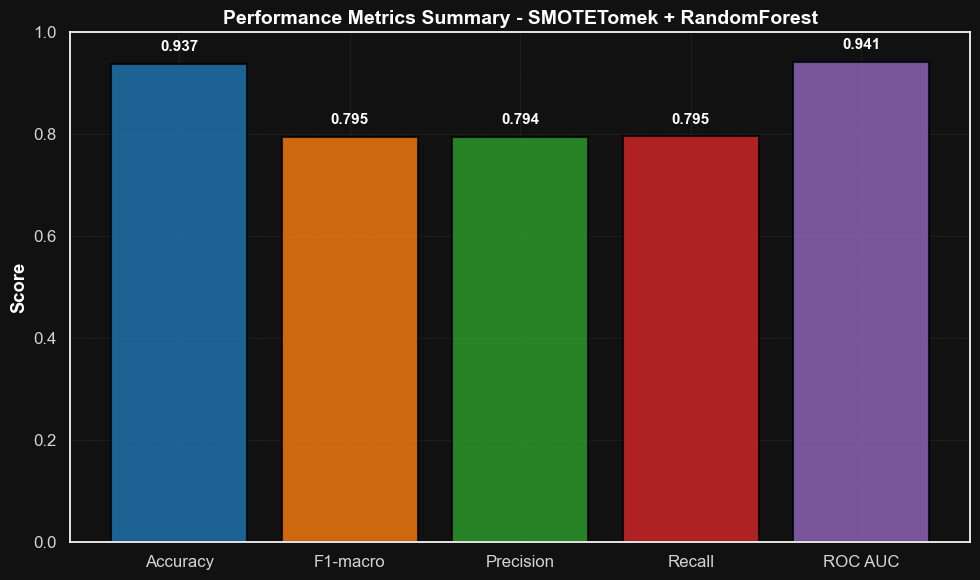

✅ Analisi SMOTETomek + RandomForest completata!
📊 Tutti i grafici generati correttamente


In [19]:
# === GRAFICI SEPARATI E PULITI ===
# 1. ROC Curve
plt.figure(figsize=(8, 6))
RocCurveDisplay.from_predictions(
    y_test, y_proba_smotetomek,
    name=f'SMOTETomek RF (AUC = {roc_auc:.3f})',
    color='darkorange',
    linewidth=2
)
plt.plot([0, 1], [0, 1], 'k--', alpha=0.6)
plt.title('ROC Curve - SMOTETomek + RandomForest', fontweight='bold', fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Precision-Recall Curve
plt.figure(figsize=(8, 6))
PrecisionRecallDisplay.from_predictions(
    y_test, y_proba_smotetomek,
    name='SMOTETomek RF',
    color='darkgreen',
    linewidth=2
)
plt.title('Precision-Recall Curve - SMOTETomek + RandomForest', fontweight='bold', fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Confusion Matrix
plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Non-Explicit', 'Explicit']
)
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - SMOTETomek + RandomForest', fontweight='bold', fontsize=14)
plt.grid(False)
plt.tight_layout()
plt.show()

# 4. Distribuzione Probabilità Predette
plt.figure(figsize=(10, 6))
plt.hist(y_proba_smotetomek[y_test == 0], bins=30, alpha=0.7,
         label='Non-Explicit (0)', color='skyblue', density=True)
plt.hist(y_proba_smotetomek[y_test == 1], bins=30, alpha=0.7,
         label='Explicit (1)', color='salmon', density=True)
plt.axvline(x=0.5, color='red', linestyle='--', linewidth=2, alpha=0.8,
            label='Threshold = 0.5')
plt.xlabel('Predicted Probability', fontweight='bold')
plt.ylabel('Density', fontweight='bold')
plt.title('Predicted Probability Distribution by Class', fontweight='bold', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Summary Metriche
plt.figure(figsize=(10, 6))
metrics = ['Accuracy', 'F1-macro', 'Precision', 'Recall', 'ROC AUC']
values = [acc, f1, precision, recall, roc_auc]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

bars = plt.bar(metrics, values, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
plt.ylim(0, 1)
plt.title('Performance Metrics Summary - SMOTETomek + RandomForest',
          fontweight='bold', fontsize=14)
plt.ylabel('Score', fontweight='bold')

# Valori sopra le barre
for bar, value in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
             f'{value:.3f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("✅ Analisi SMOTETomek + RandomForest completata!")
print("📊 Tutti i grafici generati correttamente")


# Imbalanced Learning Techniques Comparison

## Performance Metrics Comparison

| **Technique** | **F1-score (macro)** | **Precision (macro)** | **Recall (macro)** | **ROC AUC** | **Recall Class 1** | **Precision Class 1** |
|-------------|----------------------|------------------------|---------------------|-------------|---------------------|-------------------------|
| **Baseline (No Balancing)** | 0.7600 | **0.9241** | 0.6954 | **0.9448** | 0.3947 | **0.9011** |
| **SMOTE** | **0.7951** | 0.7938 | 0.7963 | 0.9411 | **0.6277** | 0.6219 |
| **Tomek + Undersampling** | 0.6688 | 0.6428 | **0.8415** | 0.9242 | **0.8695** | 0.3002 |
| **SMOTE + Tomek** | 0.7947 | 0.7942 | 0.7951 | 0.9408 | 0.6250 | 0.6230 |

---

## Technique Analysis

### Baseline (No Balancing)
- **Characteristics**: Conservative model that heavily favors the majority class
- **Strengths**: Excellent precision (92.4%), maximum ROC AUC (94.5%)
- **Weaknesses**: Poor minority class recall (39.5%) leading to high false negative rate
- **Use case**: When avoiding false positives is critical and missing true positives is acceptable

### SMOTE (Synthetic Minority Oversampling)
- **Characteristics**: Optimal balance between precision and recall
- **Strengths**: Best F1-macro score (79.5%), minority class recall nearly doubled vs baseline
- **Weaknesses**: Slightly reduced precision compared to baseline
- **Use case**: **Optimal choice for most scenarios** - ideal equilibrium between metrics

### Tomek + Undersampling
- **Characteristics**: Aggressive approach that maximizes sensitivity
- **Strengths**: Excellent minority class recall (86.9%), maximum macro recall
- **Weaknesses**: Very low class 1 precision (30%) resulting in many false positives
- **Use case**: When capturing all positive cases is critical (e.g., medical diagnosis, fraud detection)

### SMOTE + Tomek (Hybrid)
- **Characteristics**: Combines oversampling with boundary cleaning
- **Strengths**: Performance very similar to pure SMOTE
- **Weaknesses**: Additional complexity without significant benefits
- **Use case**: When maximum data cleaning is desired, though pure SMOTE is often sufficient

---

## Winner: SMOTE

### Why SMOTE is the best choice:

1. **Optimal F1-score macro**: 0.7951 (highest among all techniques)
2. **Ideal balance**: Good compromise between precision (79.4%) and recall (79.6%)
3. **Minority class recall improvement**: 62.8% (vs 39.5% baseline) - **59% improvement**
4. **Simplicity**: Straightforward implementation without additional complexity
5. **Robustness**: Stable ROC AUC (94.1%) - minimal loss vs baseline

### Key performance metrics:
- **Class 1 Recall**: from 39.5% to **62.8%** (+23.3 percentage points)
- **F1-score macro**: from 76.0% to **79.5%** (+3.5 percentage points)
- **ROC AUC loss**: only -0.37 percentage points (negligible)

---

## Final Recommendations

- **Use SMOTE** for most imbalanced classification problems
- **Consider Tomek + Undersampling** only when false negative cost is extremely high
- **Avoid baseline** in fairness contexts or when minority class is important
- **SMOTE + Tomek** does not add significant value over pure SMOTE

### Bottom Line:
**SMOTE provides the best trade-off** between performance, simplicity, and interpretability for this music classification dataset.